# 03 · Models: honest evaluation against a baseline and a ceiling

All models are evaluated with **GroupKFold by `composition_group_id`** (5 folds × 3 seeds): grades with identical
chemistry never sit on both sides of a split. Every score is compared with

* the **family-median baseline** (what an engineer gets from a handbook table), and
* the **irreducible-error ceiling** from notebook 01 (processing is not in the data).

Logic: `src/analysis/modeling.py`, `evaluation.py`, `clustering.py`, `substitutes.py`, `train.py`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

from src.analysis import plotting as P
P.apply_theme()

def show(fig, name):
    path = P.save(fig, name)
    display(Image(filename=str(path)))

In [2]:
import logging; logging.basicConfig(level=logging.WARNING)
from src.analysis.cleaning import load_clean_grades, load_pipeline_meta
from src.analysis.constants import CLEAN_LISTINGS_CSV
from src.analysis import evaluation as EV, modeling as M, viz_models as VM
grades = load_clean_grades(); listings = pd.read_csv(CLEAN_LISTINGS_CSV)
rare = load_pipeline_meta()["rare_elements"]
ev = EV.run_evaluation(grades, listings, rare)      # every CV experiment, run once
EV.save_evaluation(ev)
m = ev.measured
print("measured grades:", len(m), "| composition groups:", m.composition_group_id.nunique())
pd.Series(ev.ceiling.as_dict())

C:\Users\PRIYANSH\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(


C:\Users\PRIYANSH\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(


C:\Users\PRIYANSH\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(


C:\Users\PRIYANSH\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(


C:\Users\PRIYANSH\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(


...

C:\Users\PRIYANSH\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(


C:\Users\PRIYANSH\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(


C:\Users\PRIYANSH\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


measured grades: 1382 | composition groups: 1296


oracle_mae                   9.908
oracle_rmse                 54.365
oracle_r2                    0.950
n_measured               1,382.000
n_groups                 1,296.000
multi_member_groups         37.000
multi_member_grades        123.000
groups_with_spread          28.000
within_group_mae           111.319
within_group_rmse          182.231
within_group_sd_pooled     217.934
dtype: float64

## 1 · Tensile-strength regression

,model,features,MAE_mean,MAE_std,RMSE_mean,R2_mean,R2_std,oof_MAE,oof_R2
8,Gradient boosting (tuned),composition+family,56.643,6.938,111.113,0.775,0.078,56.011,0.771
7,Gradient boosting,composition+family,56.708,6.526,110.014,0.781,0.075,55.634,0.785
5,Random forest,composition+family,57.792,6.536,113.517,0.762,0.101,56.899,0.782
6,Gradient boosting,composition,72.114,6.866,144.800,0.627,0.101,71.979,0.628
4,Random forest,composition,72.949,7.749,148.408,0.614,0.091,72.089,0.630
3,Ridge,composition+family,114.295,12.638,178.319,0.398,0.291,113.514,0.470
1,Family median (baseline),family only,114.805,9.573,177.827,0.413,0.242,115.937,0.436
2,Ridge,composition,141.894,15.886,244.242,-0.053,0.208,143.038,-0.047
0,Global median,family only,148.267,13.662,243.858,-0.033,0.025,148.292,-0.027


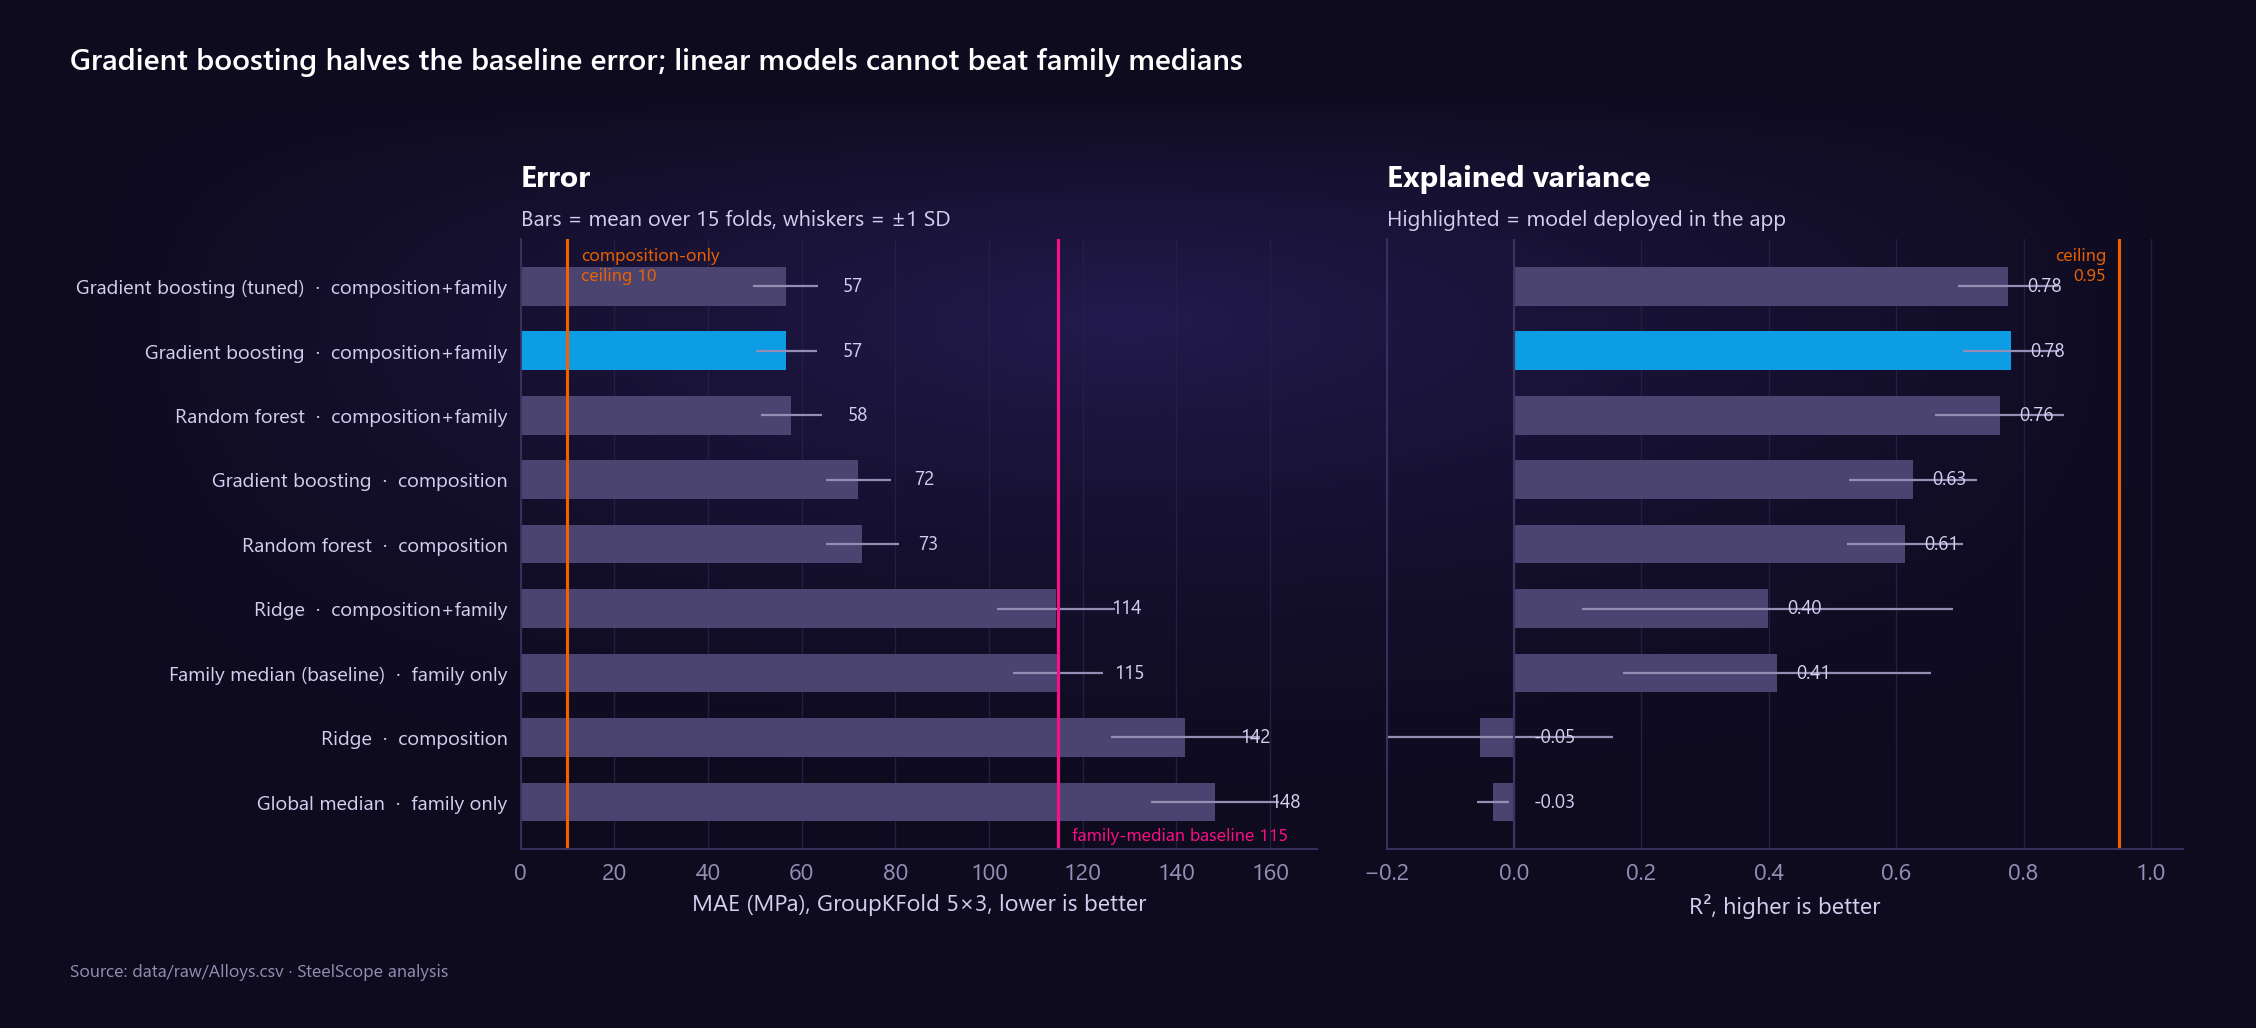

In [3]:
cols = ["model", "features", "MAE_mean", "MAE_std", "RMSE_mean", "R2_mean", "R2_std", "oof_MAE", "oof_R2"]
display(ev.reg_table[cols].sort_values("MAE_mean"))
show(VM.model_comparison(ev.reg_table, ev.baseline_mae, ev.ceiling, EV.CHOSEN_REGRESSOR), "03_model_comparison")

**Reading the table.**

* The **family-median baseline** is the bar to beat. **Ridge does not beat it**: element effects change sign
  between families (notebook 02, Q2), and a pooled linear model cannot express that.
* Tree ensembles learn those family-conditional, non-linear effects and roughly **halve the baseline MAE**.
  Adding family and product form to composition helps every model.
* Nested GroupKFold tuning of the GBM (last row) gives no gain over the fixed settings, so the simpler fixed
  configuration is deployed.
* The gap to the ceiling is real but bounded. Most of it sits in grades whose chemistry is shared with other
  tempers (section 3).

## 2 · Why GroupKFold: the leakage demonstration

,setup,n_rows,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
0,"Listing rows incl. imputed TS, random KFold",2610,59.006,5.146,112.683,16.443,0.721,0.069
1,"Listing rows, imputed dropped, random KFold",2141,38.472,3.681,81.842,19.385,0.881,0.034
2,"One row per grade, random KFold",1382,53.924,5.421,105.816,25.452,0.806,0.045
3,"One row per grade, GroupKFold (used)",1382,56.708,6.526,110.014,21.935,0.781,0.075


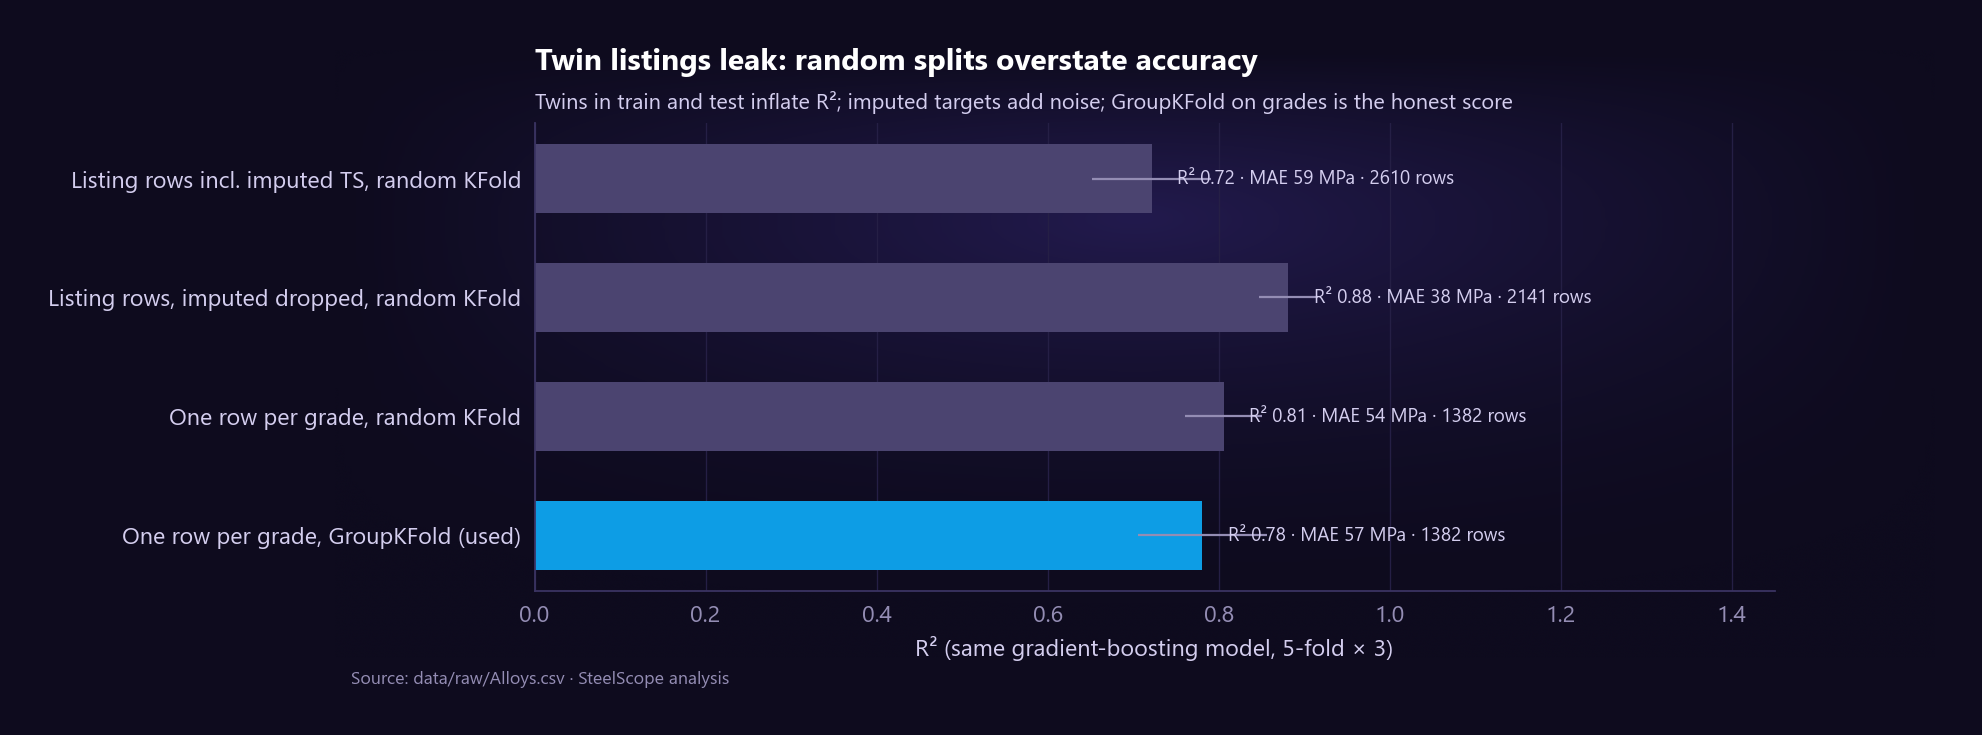

In [4]:
display(ev.leakage)
show(VM.leakage_demo(ev.leakage), "03_leakage_demo")

The same model looks far better on random splits of the listing rows, because a grade's twin listing sits in
the training fold. Keeping the imputed targets instead adds noise. Even at grade level, a random split lets
processing variants of one chemistry leak across folds. **Only the last row is an honest estimate** of how the
model does on a chemistry it has not seen.

## 3 · Where the model errs

OOF MAE: unique composition 46.4 MPa (n=1259), shared composition 150.3 MPa (n=123); median AE 27.9 MPa


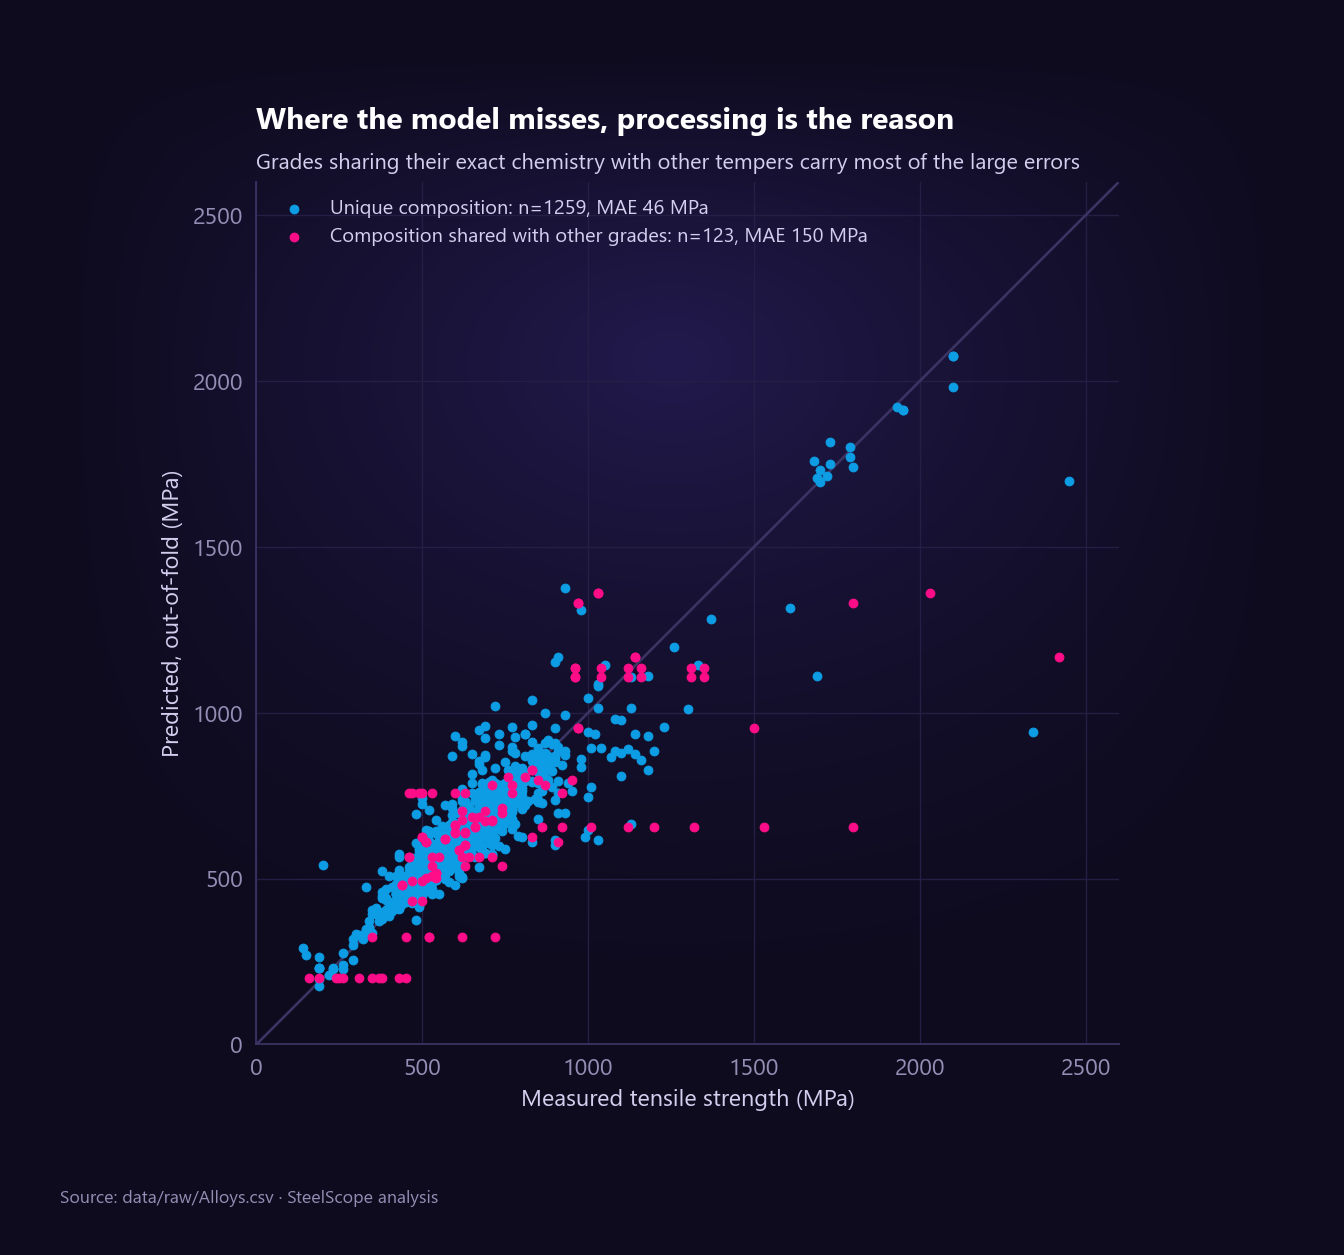

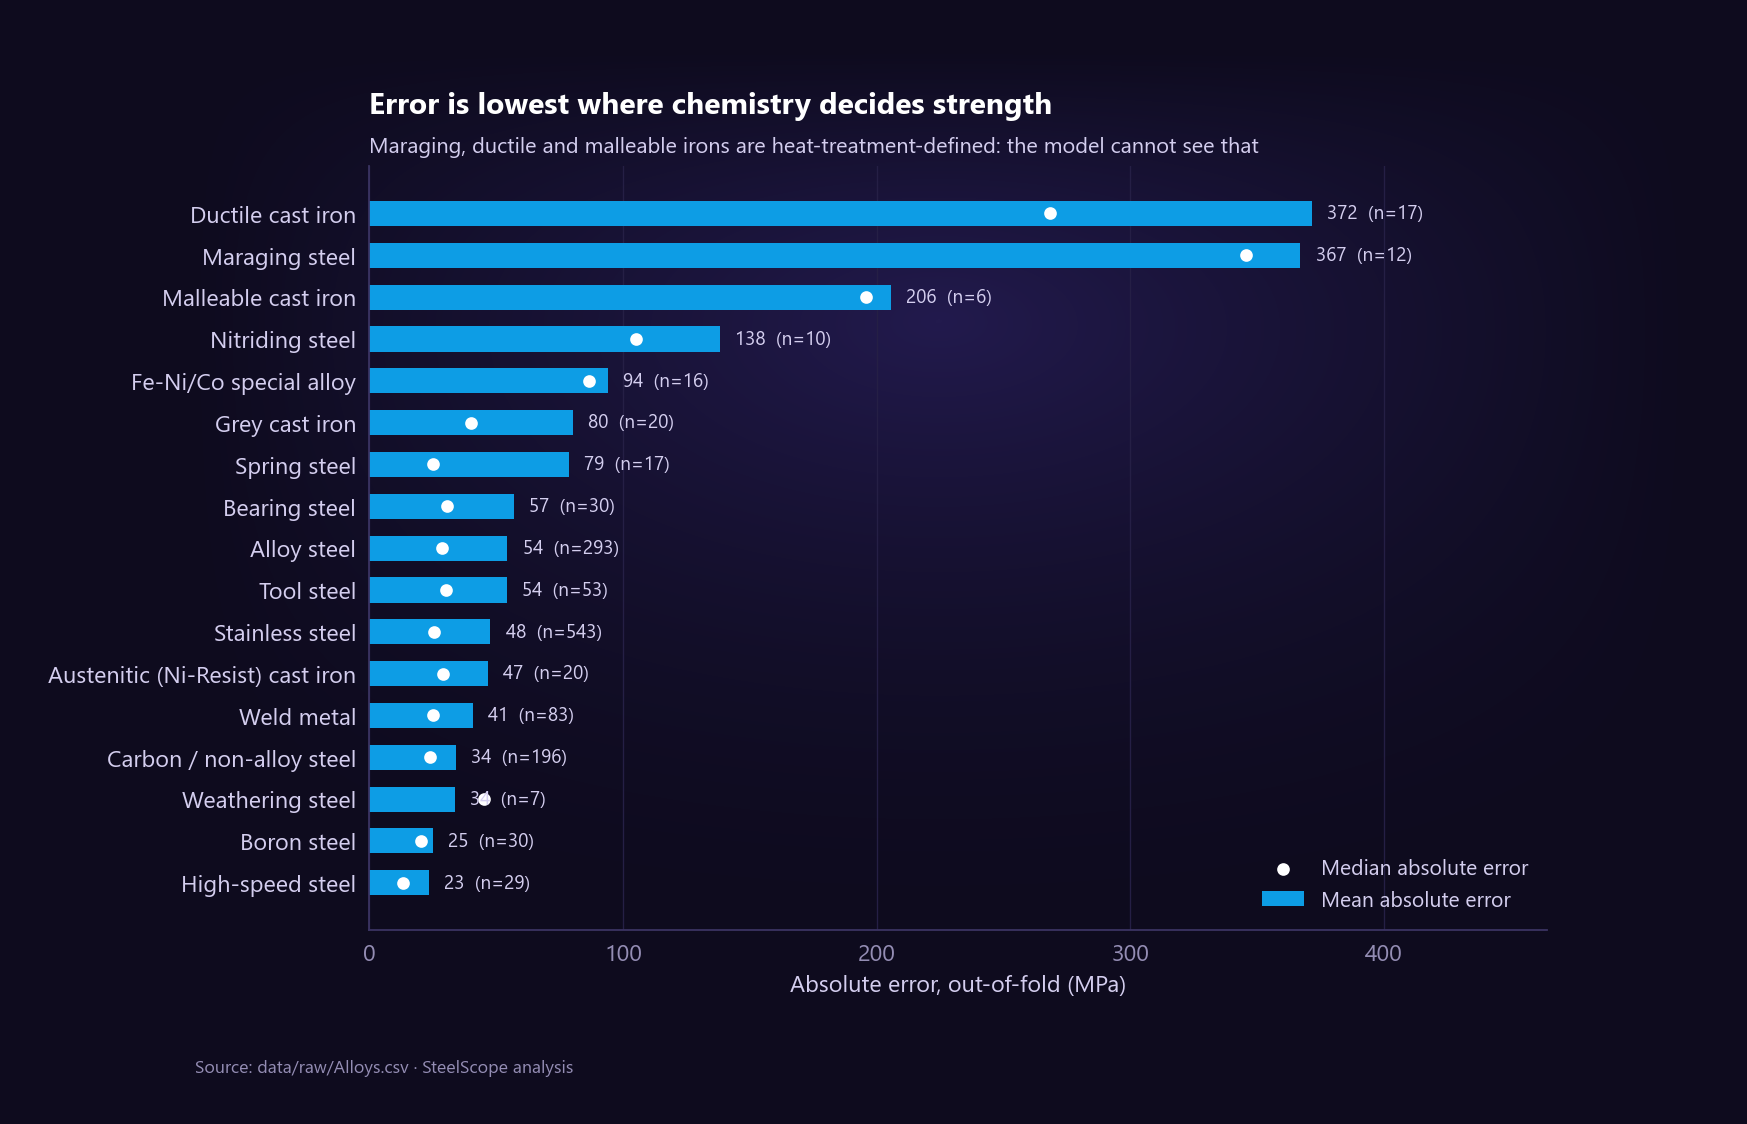

In [5]:
err = (ev.chosen_oof - m[M.TARGET]).abs()
shared = m.composition_group_n_measured > 1
print(f"OOF MAE: unique composition {err[~shared].mean():.1f} MPa (n={(~shared).sum()}), "
      f"shared composition {err[shared].mean():.1f} MPa (n={shared.sum()}); median AE {err.median():.1f} MPa")
show(VM.pred_vs_actual(m, ev.chosen_oof), "03_pred_vs_actual")
show(VM.error_by_family(m, ev.chosen_oof), "03_error_by_family")

## 4 · Strength-class classifier (TS never used as a feature)

,model,macro_F1_mean,macro_F1_std,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std,oof_macro_F1,oof_balanced_accuracy,recall_class_0,recall_class_1,recall_class_2
0,Family majority (baseline),0.613,0.091,0.613,0.115,0.636,0.029,0.638,0.625,0.609,0.552,0.714
1,Logistic regression (balanced),0.707,0.072,0.788,0.072,0.767,0.028,0.703,0.760,0.739,0.843,0.698
2,Gradient boosting (balanced),0.887,0.051,0.903,0.054,0.892,0.021,0.885,0.915,0.957,0.890,0.897
3,"GBM regressor, thresholded",NaN,NaN,NaN,NaN,NaN,NaN,0.867,0.890,0.913,0.844,0.914


,pred 0,pred 1,pred 2
true 0,22,1,0
true 1,6,577,65
true 2,0,73,638


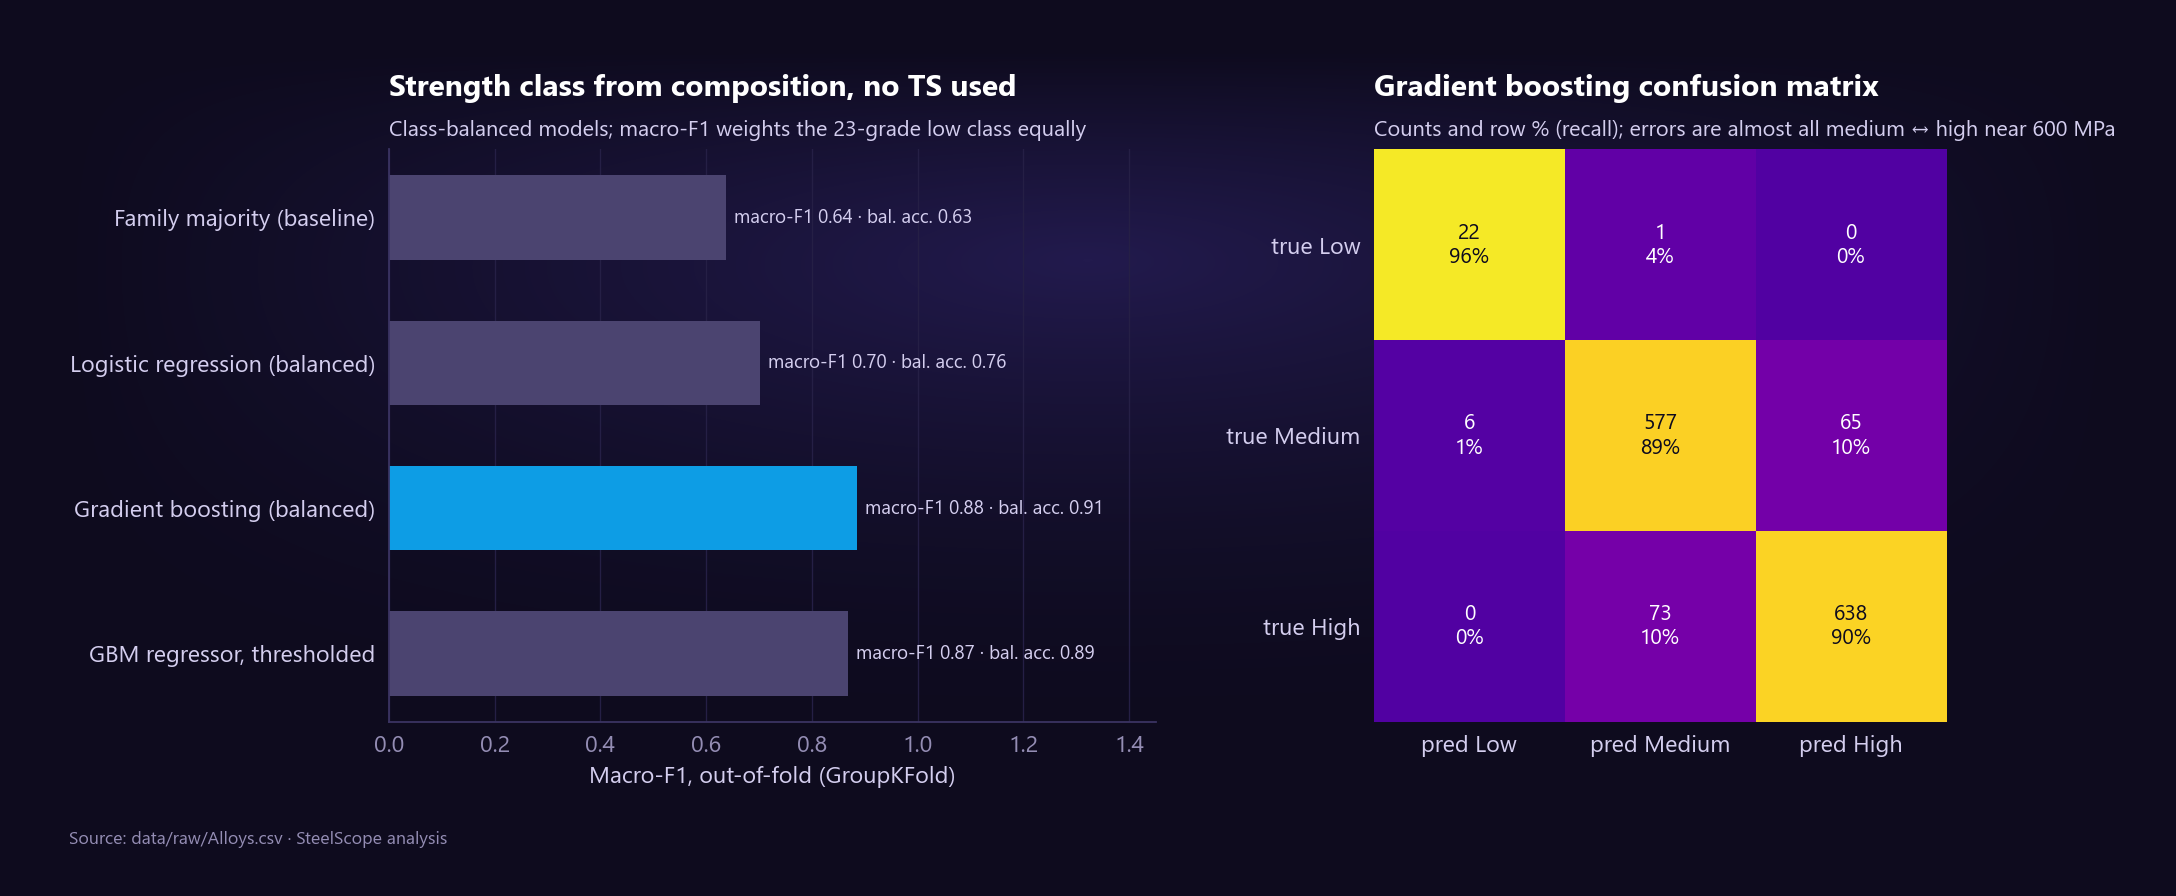

In [6]:
display(ev.clf_table.round(3))
cm = M.confusion(ev.y_class, ev.clf_results["Gradient boosting (balanced)"].oof.astype(int))
display(cm)
show(VM.classifier_results(ev.clf_table, cm), "03_classifier")

Class-balanced gradient boosting clearly beats the family-majority baseline on macro-F1 and recovers almost
the whole low class. Errors concentrate at the medium/high boundary (600 MPa), where a few MPa decide the
label. Thresholding the regressor's prediction is nearly as good, a useful consistency check between the
two models.

## 5 · What drives the predictions

,mae_increase_mean,mae_increase_sd
feature,,
family,43.310,24.940
Ni,28.790,5.550
carbon_equivalent,23.140,2.840
ni_eq,21.410,3.620
alloying_total,13.150,4.000
Mn,12.640,2.920
N,8.650,1.810
C,8.360,2.690
Si,7.850,1.940


SHAP additivity max error: 3.410605131648481e-12


family              54.400
carbon_equivalent   33.300
Ni                  30.200
ni_eq               25.700
C                   18.000
alloying_total      17.500
Mn                  14.500
N                   14.300
Mo                  13.900
Si                  12.800
Cr                  12.000
V                   10.800
dtype: float64

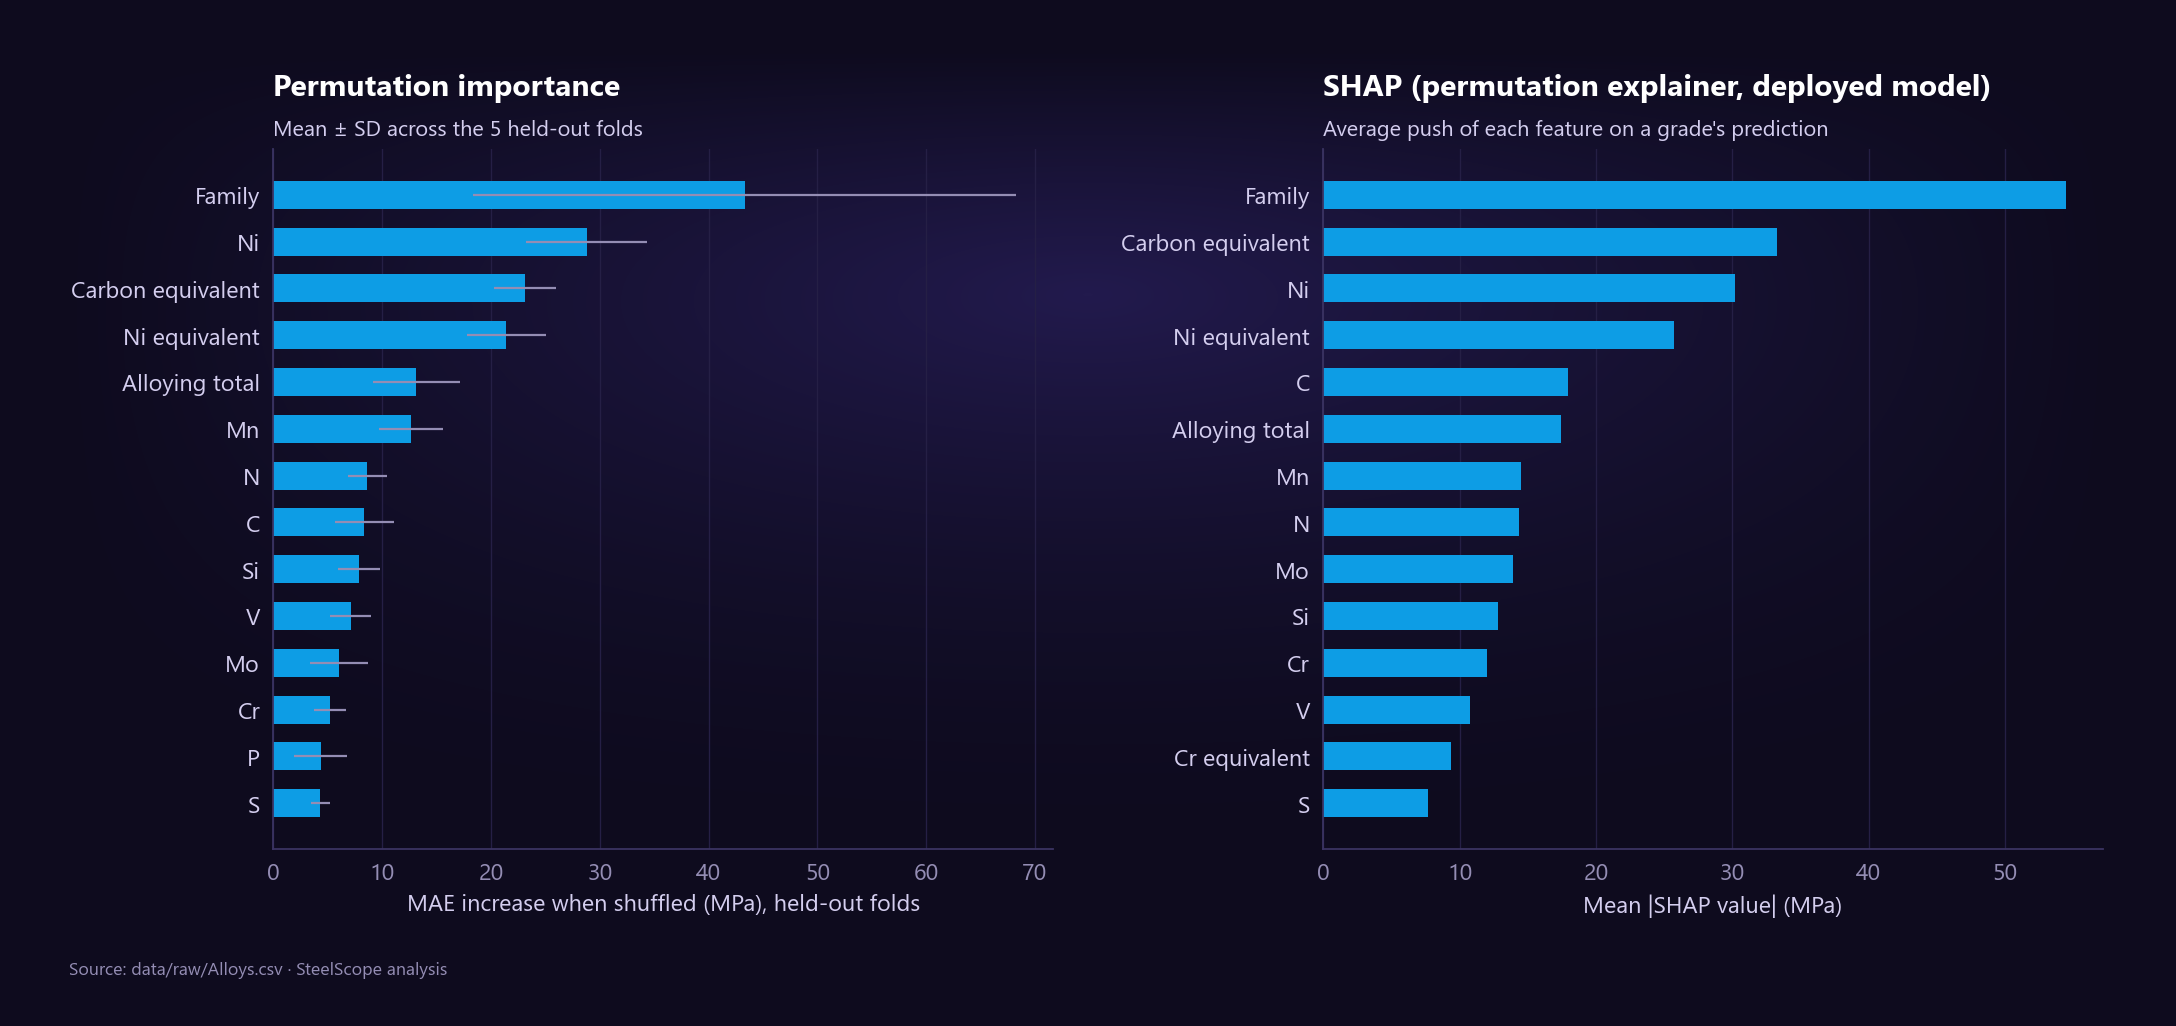

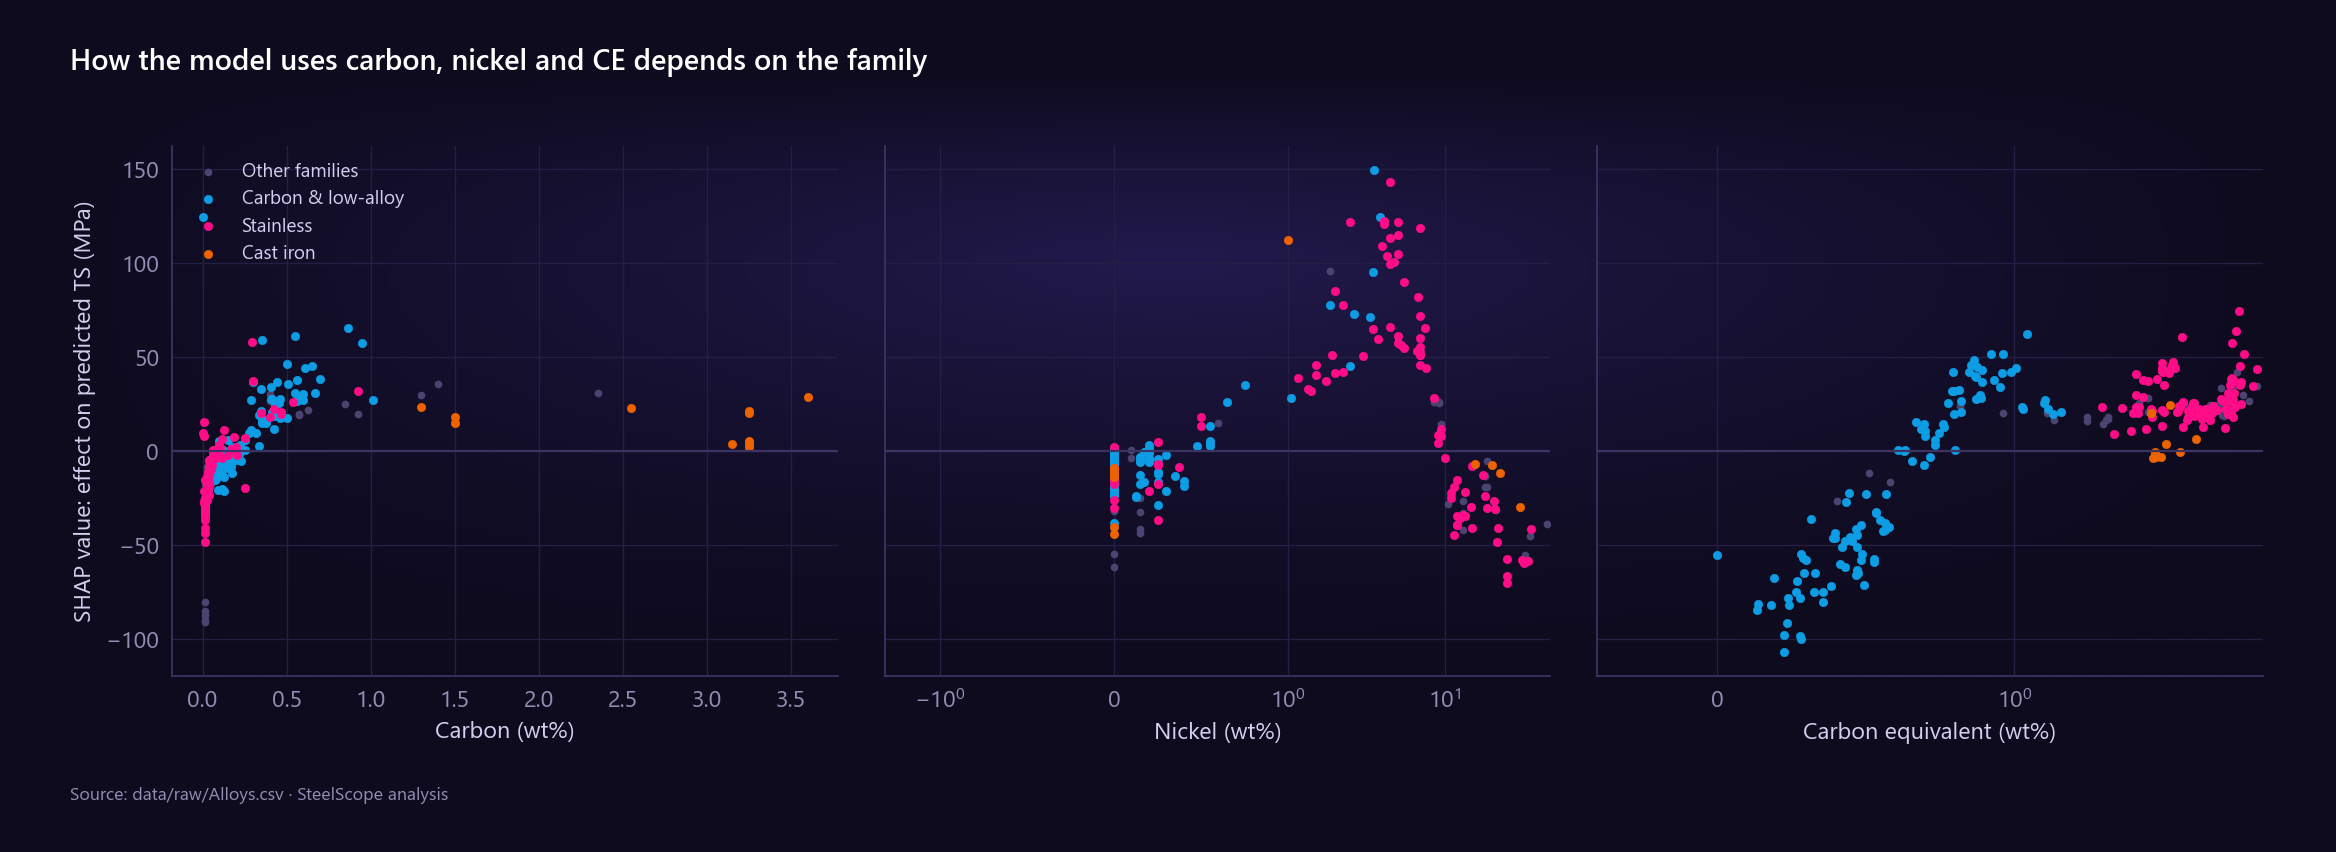

In [7]:
display(ev.perm_importance.round(2).head(15))
import shap
spec = M.feature_specs(rare)["composition+family"]; levels = M.category_levels(grades)
X = M.build_X(m, spec, levels, rare)
est = M.make_regressor("Gradient boosting", spec).fit(X, m[M.TARGET])
codes = X.copy()
for c in spec.categorical: codes[c] = X[c].cat.codes.astype(float)
cols_ = list(X.columns)
def f(a):
    d = pd.DataFrame(a, columns=cols_)
    for c in spec.categorical: d[c] = pd.Categorical.from_codes(d[c].astype(int), categories=levels[c])
    return est.predict(d)
sample = codes.sample(250, random_state=0)
background = shap.maskers.Independent(shap.utils.sample(codes, 100, random_state=0), max_samples=100)
sv = shap.PermutationExplainer(f, background, seed=0)(sample, silent=True)
print("SHAP additivity max error:", float(np.abs(sv.values.sum(1) + sv.base_values - f(sample.values)).max()))
shap_mean = pd.Series(np.abs(sv.values).mean(0), index=cols_).sort_values(ascending=False)
shap_mean.rename("mean_abs_shap_mpa").to_csv(ROOT / "reports/tables/shap_importance.csv")
display(shap_mean.round(1).head(12))
show(VM.importance(ev.perm_importance, shap_mean), "03_feature_importance")
show(VM.shap_dependence(X.loc[sample.index].reset_index(drop=True), sv.values, cols_, m.loc[sample.index, "family"]),
     "03_shap_dependence")

Permutation importance (held-out folds) and SHAP (deployed model) agree on the top of the ranking: **family**
first, then carbon equivalent, nickel and carbon. The dependence plots show *why* one global coefficient fails:
the same carbon or nickel content pushes the prediction differently depending on the family.

## 6 · Prediction intervals for the Strength Estimator

{'nominal': 0.8, 'coverage_raw': 0.613, 'coverage_calibrated': 0.798, 'mean_width_calibrated': 203.541, 'q_hat_final': 18.808}


,n,coverage,mean_width
type,,,
Composition shared with other grades,123,0.724,410.880
Unique composition,1259,0.805,183.284


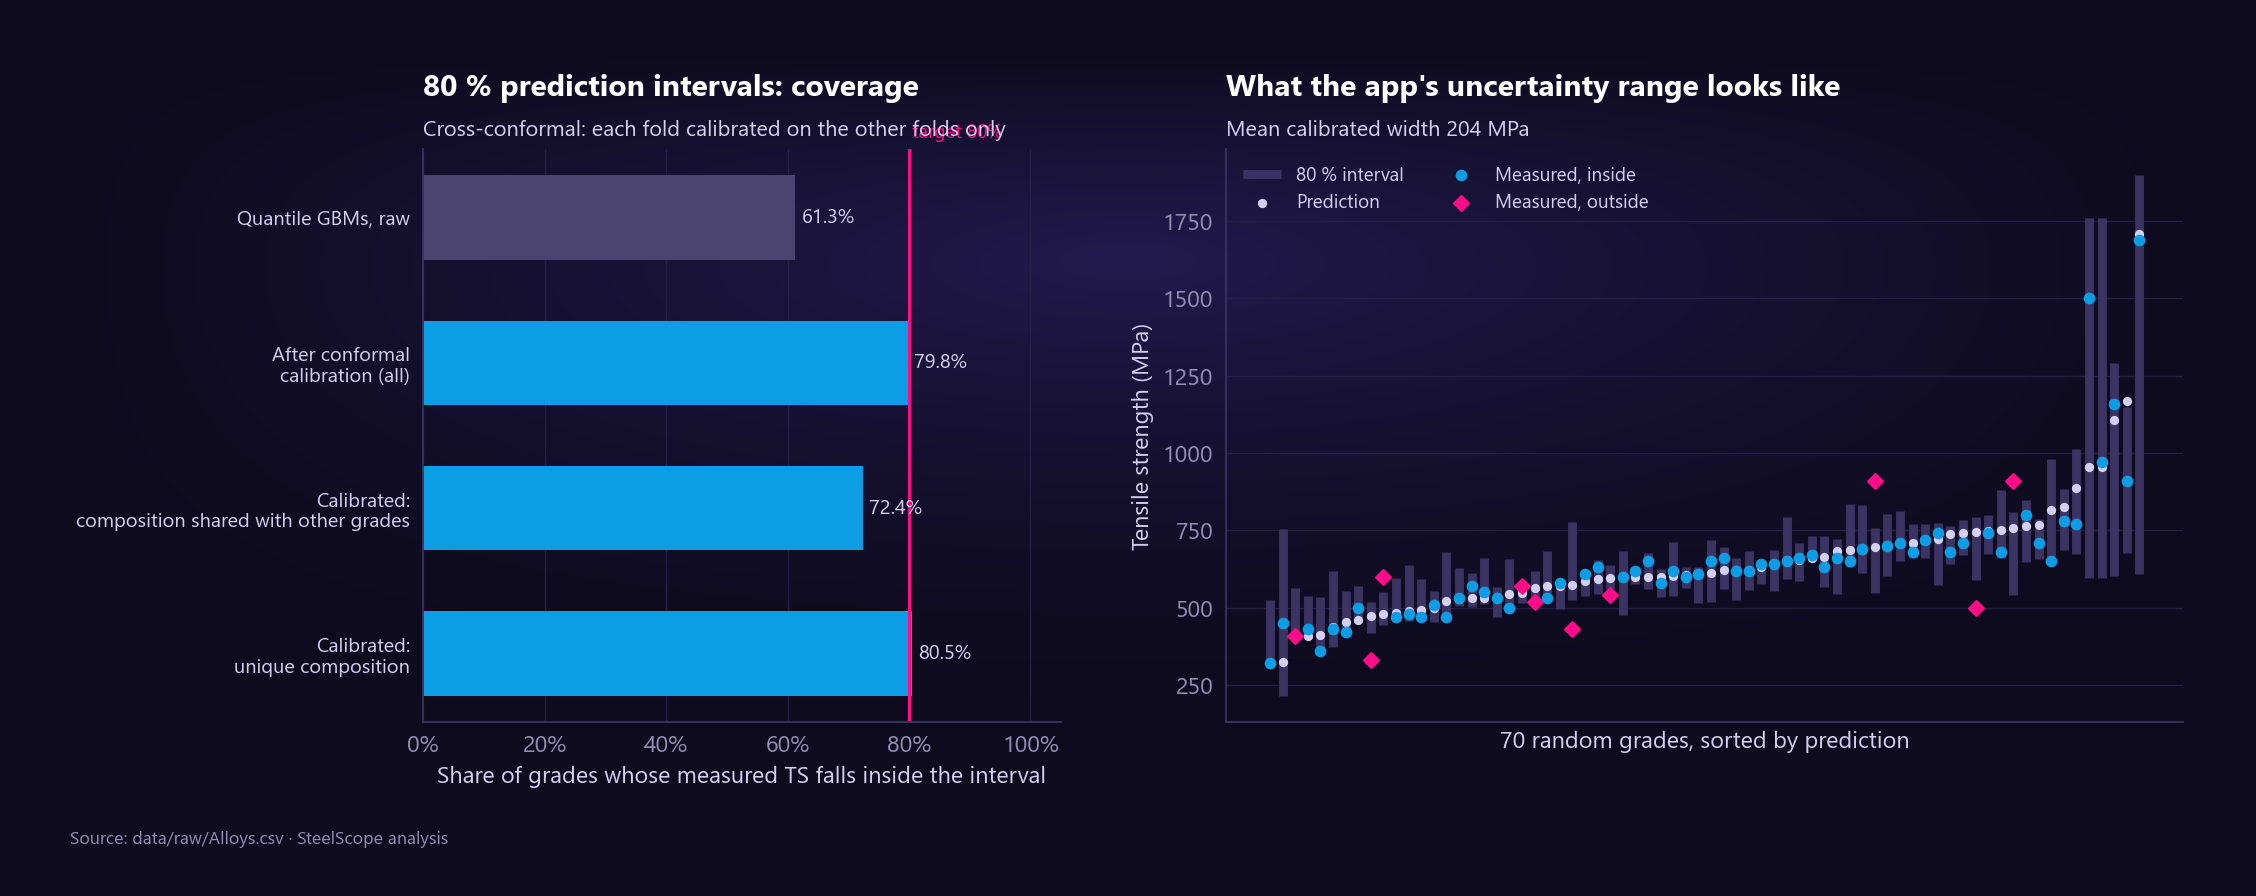

In [8]:
iv = ev.intervals
print({k: round(v, 3) for k, v in [("nominal", iv.nominal), ("coverage_raw", iv.coverage_raw),
       ("coverage_calibrated", iv.coverage_calibrated), ("mean_width_calibrated", iv.mean_width_calibrated),
       ("q_hat_final", iv.q_hat_final)]})
display(iv.by_group_type)
show(VM.interval_coverage(iv, m, ev.chosen_oof), "03_interval_coverage")

Raw quantile GBMs under-cover. A cross-conformal correction brings coverage to the 80 % target **without
looking at the fold being scored**. Coverage is lower for grades whose chemistry is shared with other tempers,
which is the processing ceiling again. The app therefore shows the range together with a
"processing / heat treatment not modelled" warning.

## 7 · Clustering: does chemistry recover the named families?

,method,vs,n_clusters,noise_share,ARI,NMI
0,KMeans,family,13,0.000,0.203,0.457
1,KMeans,family_group,13,0.000,0.408,0.451
2,HDBSCAN (non-noise),family,21,0.487,0.270,0.636
3,HDBSCAN (non-noise),family_group,21,0.487,0.243,0.526


,n,dominant_family,dominant_share,n_families,median_ts,median_alloying,signature,label
cluster,,,,,,,,
0,19,Stainless steel,0.789,2,900.000,21.650,Al↑ Cr↑ Ti↑,C0: Stainless steel (Al↑ Cr↑ Ti↑)
1,21,Stainless steel,0.714,3,600.000,15.500,S↑,C1: Stainless steel (S↑)
2,69,Stainless steel,0.826,2,600.000,30.400,Ti↑ Co↑ Ni↑,C2: Stainless steel (Ti↑ Co↑ Ni↑)
3,12,Grey cast iron,1.000,1,310.000,7.000,P↑ C↑ Si↑,C3: Grey cast iron (P↑ C↑ Si↑)
4,45,High-speed steel,0.622,5,770.000,23.850,V↑ W↑ Co↑,C4: High-speed steel (V↑ W↑ Co↑)
5,157,Stainless steel,0.936,2,730.000,37.100,N↑ Mn↑ Cr↑,C5: Stainless steel (N↑ Mn↑ Cr↑)
6,1,Stainless steel,1.000,1,750.000,37.000,B↑ Nb↑ Ni↑,C6: Stainless steel (B↑ Nb↑ Ni↑)
7,18,Alloy steel,0.444,5,660.000,4.050,Zr↑ Co↑,C7: Alloy steel (Zr↑ Co↑)
8,275,Stainless steel,0.833,4,590.000,33.800,Ni↑ Cr↑ Nb↑,C8: Stainless steel (Ni↑ Cr↑ Nb↑)


PCA explained variance (2 comps): [0.15  0.118]


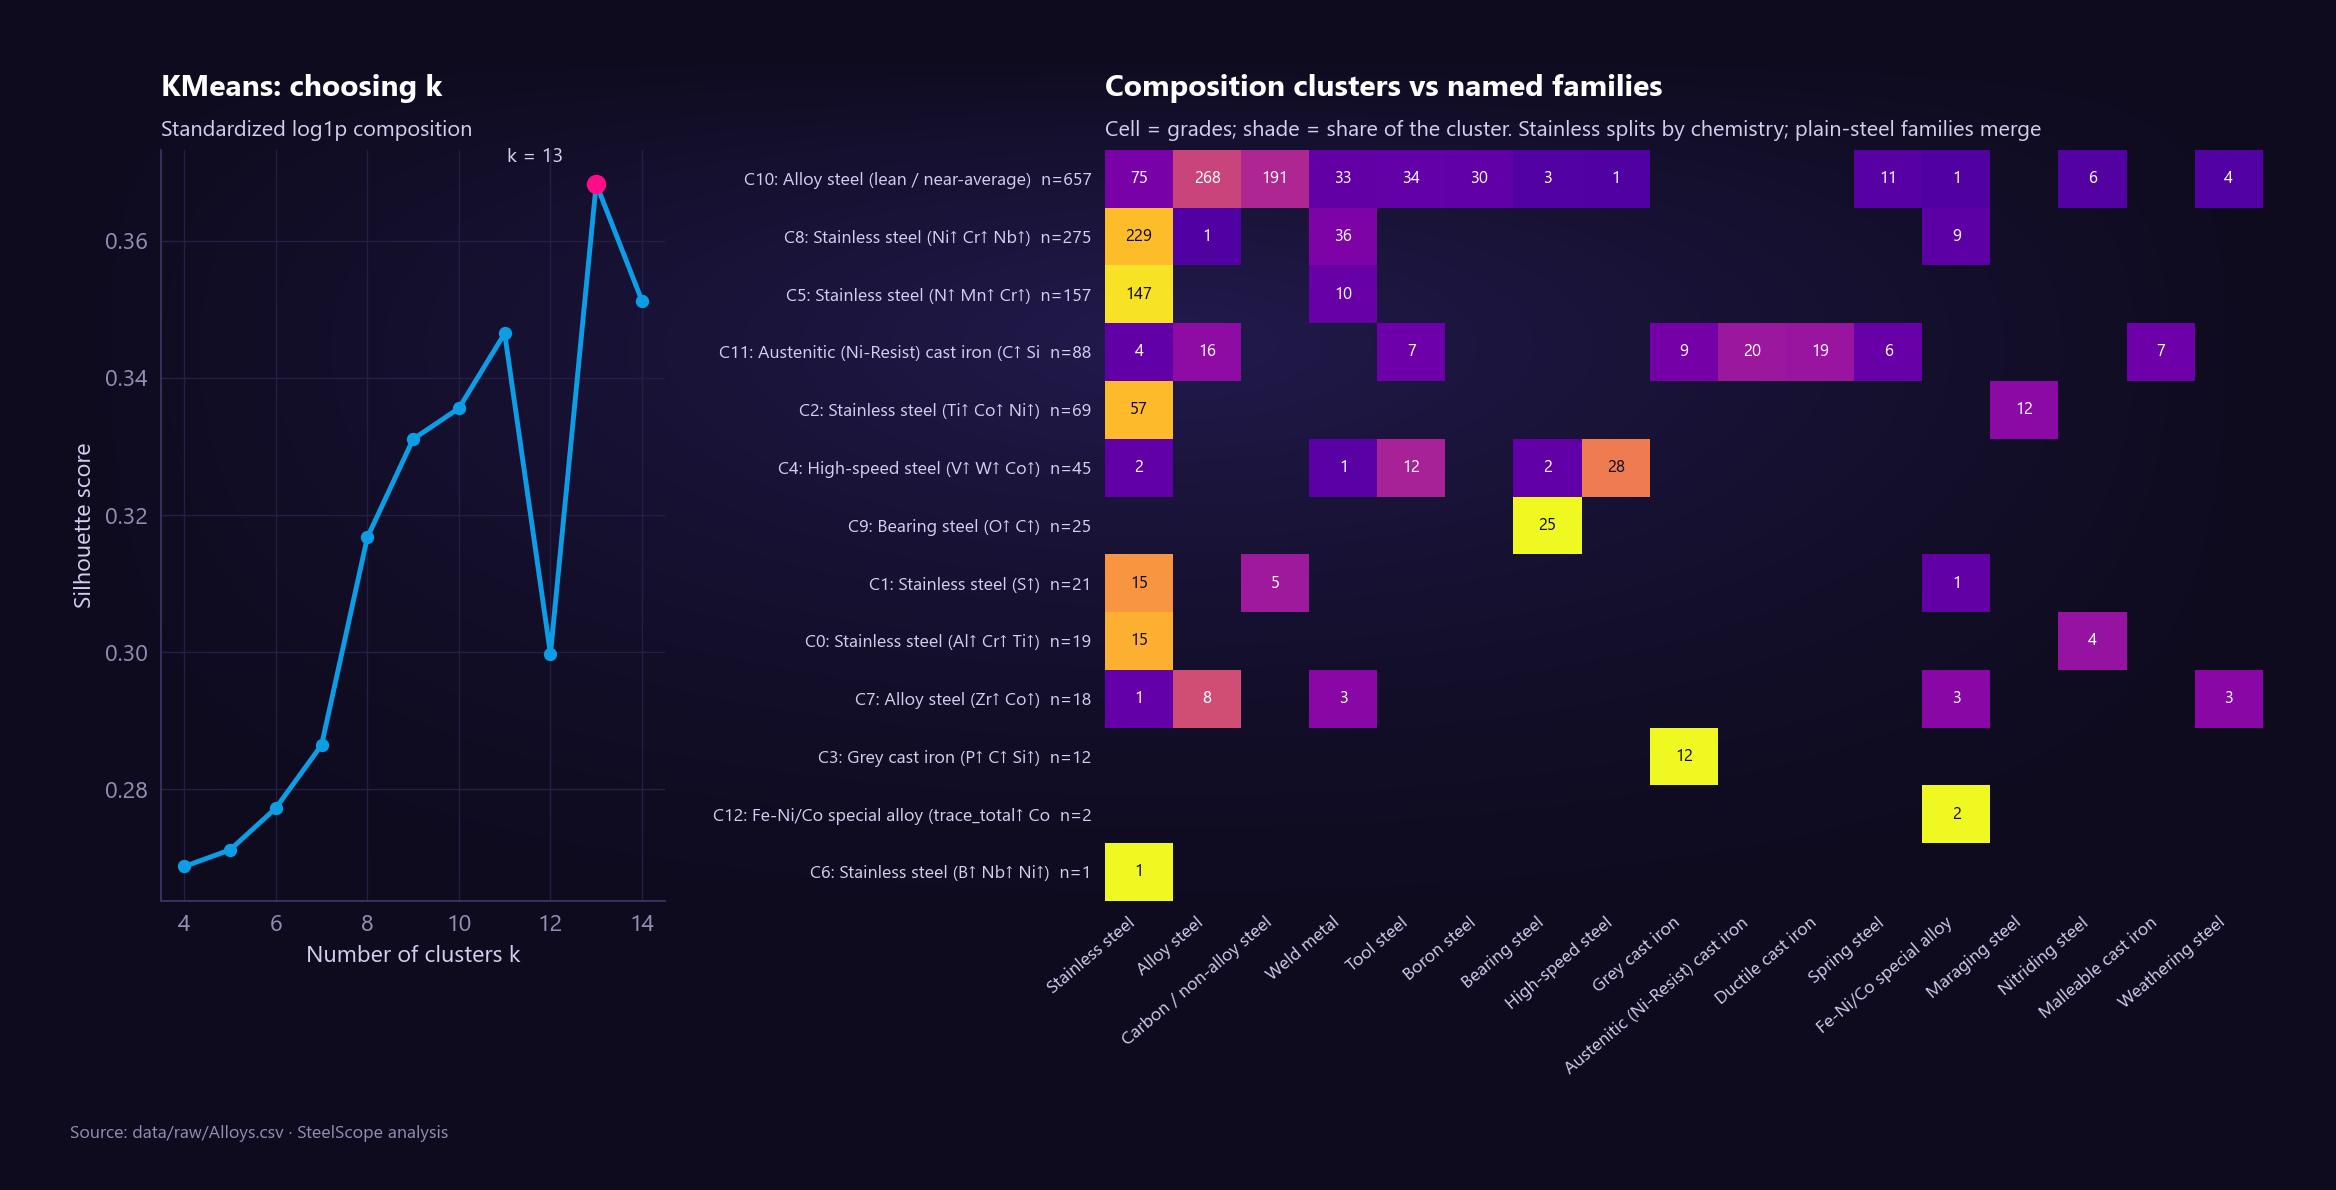

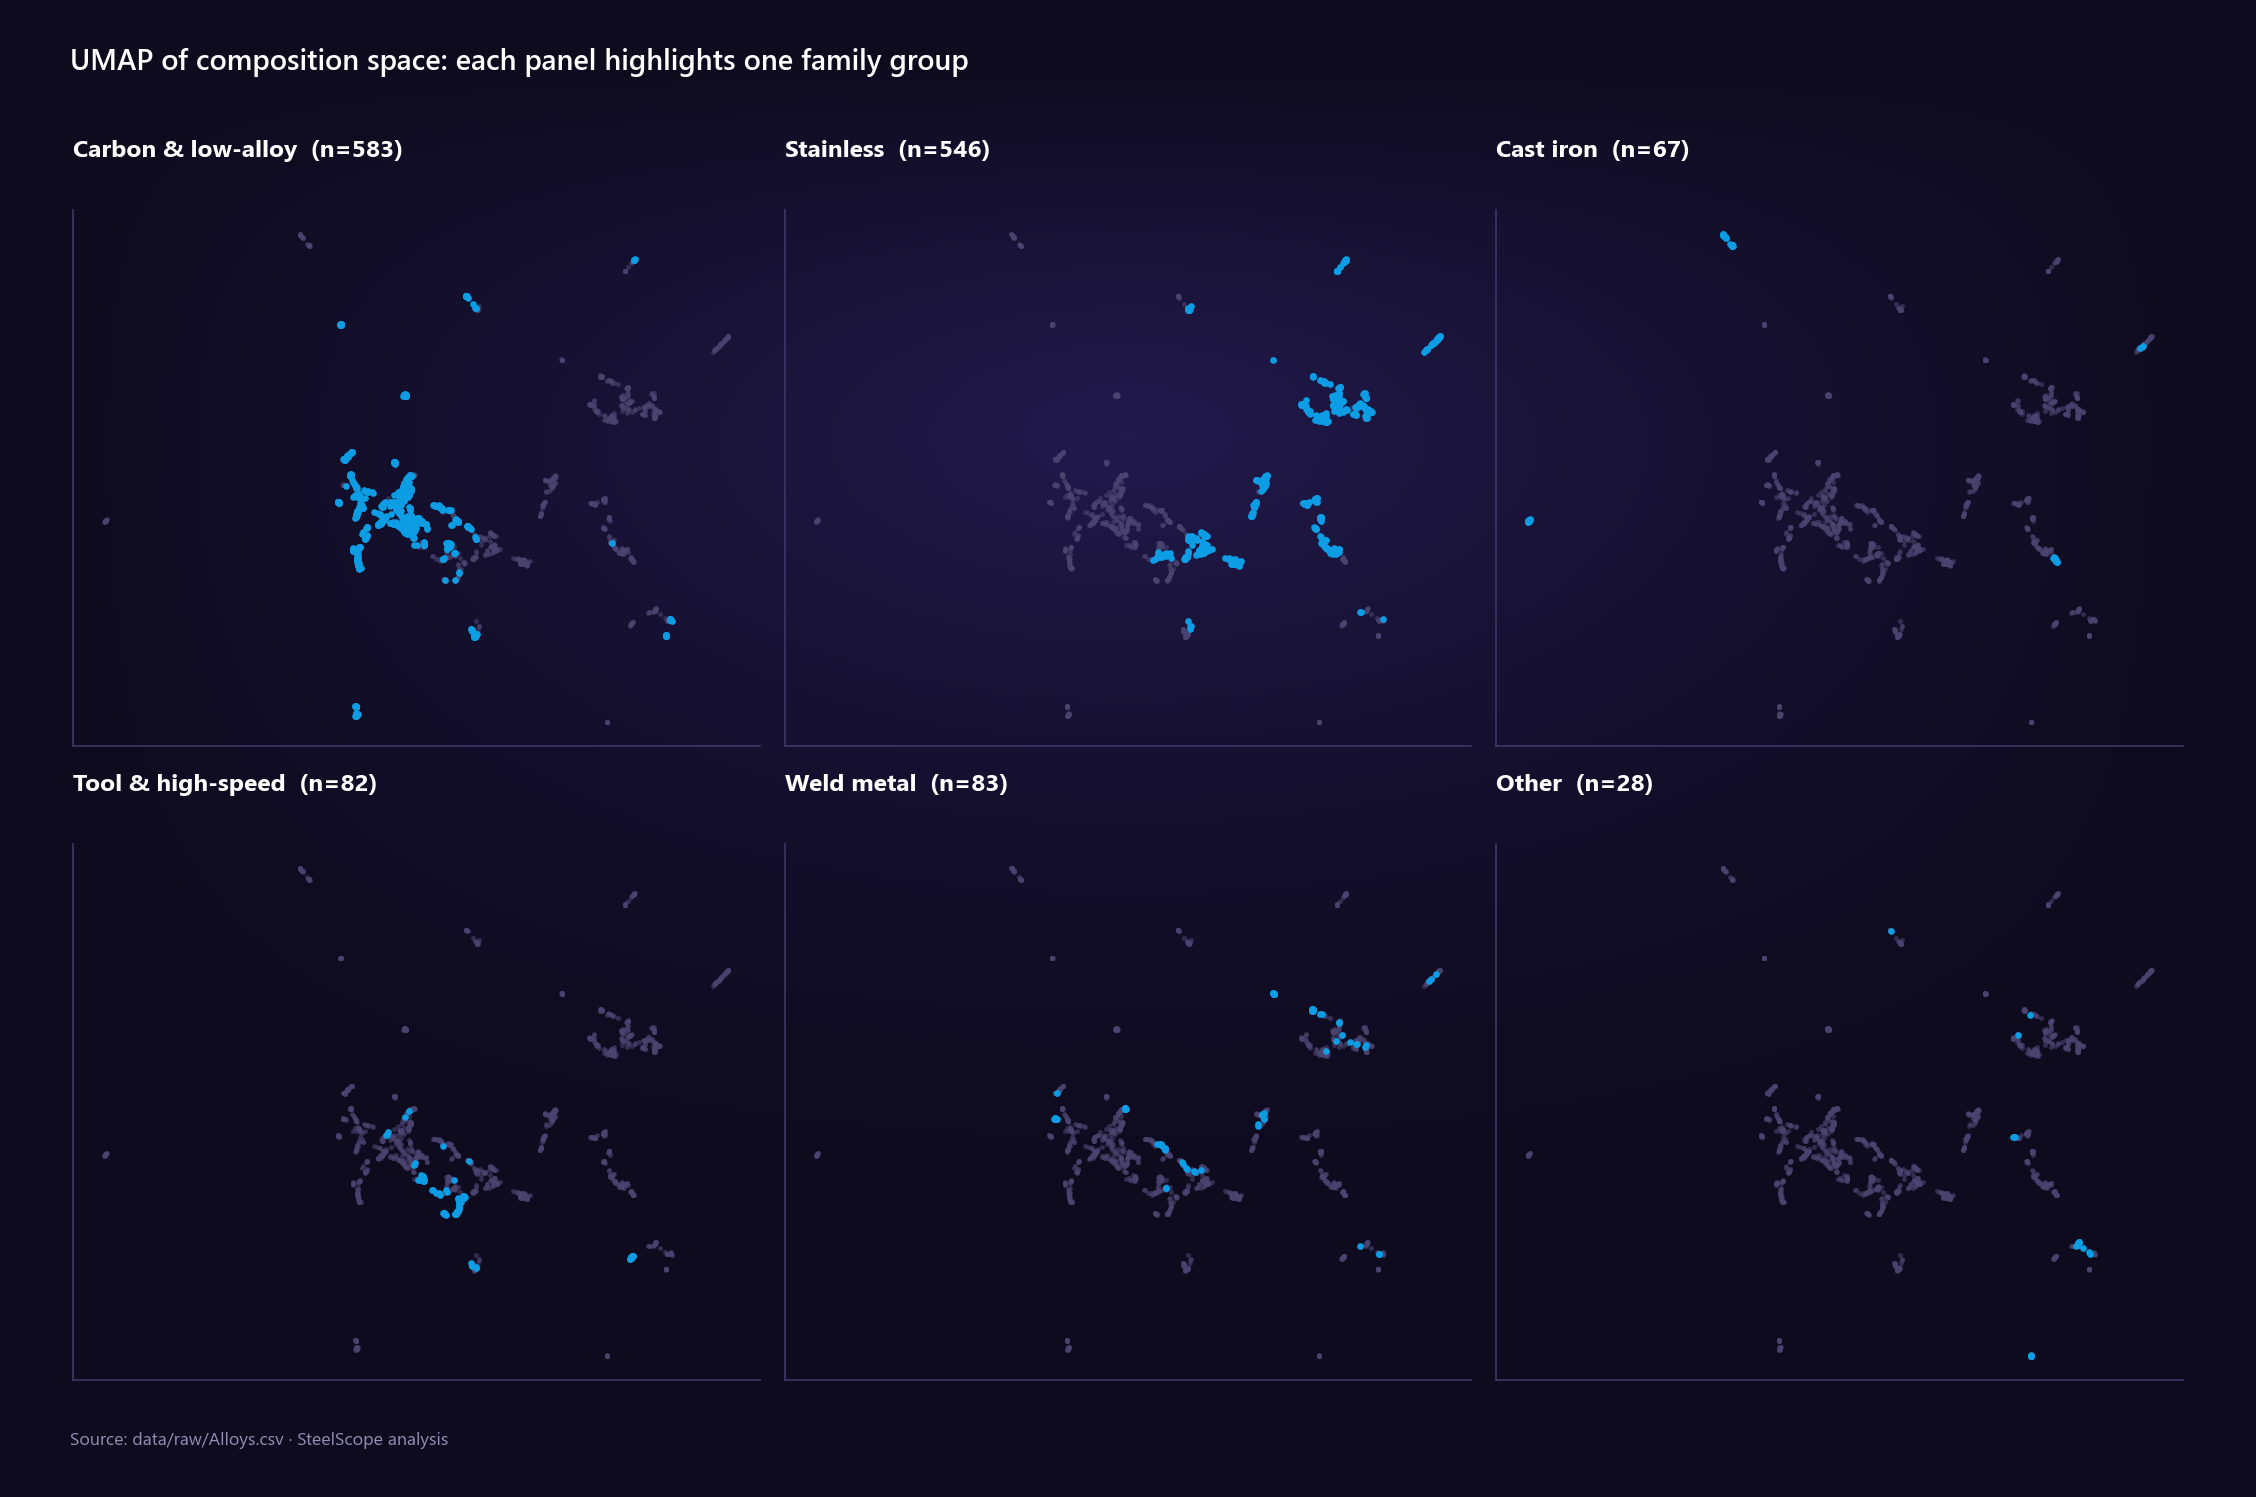

In [9]:
cl = ev.clustering
display(cl.agreement.round(3))
display(cl.profiles)
print("PCA explained variance (2 comps):", cl.pca_explained.round(3))
show(VM.clustering_overview(cl, grades), "03_clusters_vs_families")
show(VM.umap_small_multiples(cl.umap_xy, grades), "03_umap_family_groups")

Composition clusters recover the chemically distinct families (stainless sub-types, grey cast iron,
high-speed and bearing steels), but **most carbon, alloy, boron, spring, nitriding and weathering grades merge
into one lean cluster**. Those names describe application and heat treatment more than chemistry. Agreement
metrics (ARI/NMI) are moderate, and higher against the coarser family groups. HDBSCAN leaves a large share as
noise: composition space is a continuum with dense islands (standard series), not separated blobs.

## 8 · Substitute engine

,family_agree@1,family_agree@5,median_abs_dTS@1,median_abs_dLiq@1
transform,,,,
random pair (baseline),0.240,NaN,150.000,20.000
raw wt% (unscaled),0.883,0.815,30.000,0.000
z-score,0.920,0.837,40.000,0.000
sqrt + z-score,0.911,0.847,30.000,0.000
log1p + z-score,0.923,0.853,30.000,0.000


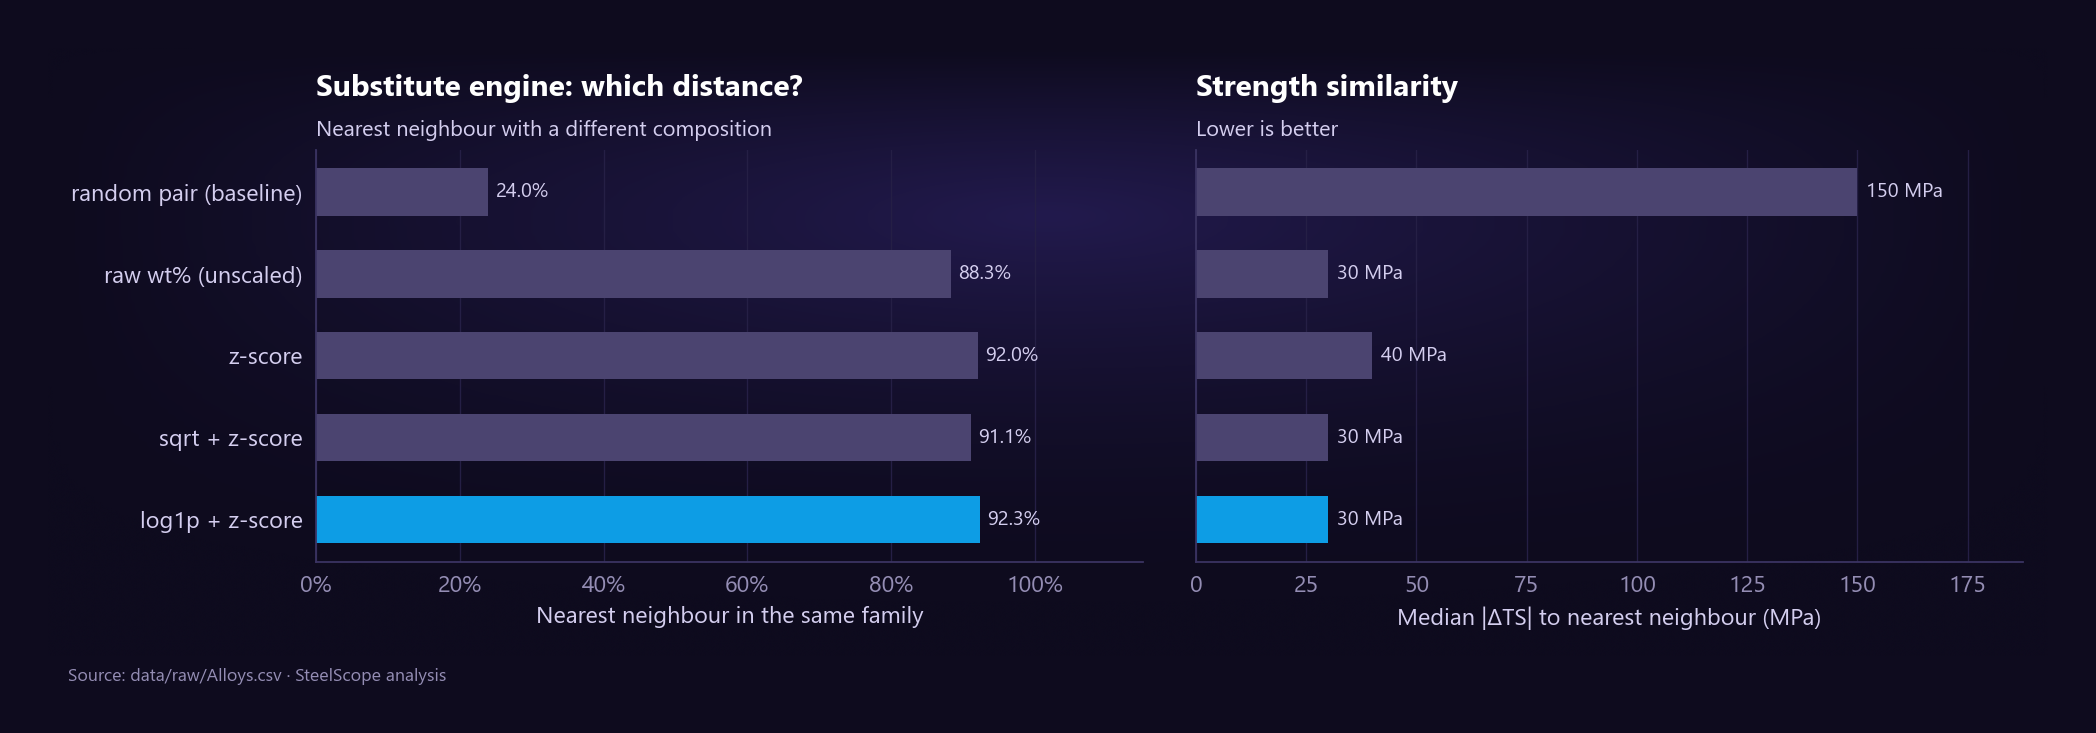

AISI 316 (S31600) Stainless Steel


,grade_id,display_name,family_label,distance,tensile_strength_mpa,delta_ts_mpa,liquidus_c,delta_liquidus_c,alloying_total,delta_alloying_total,largest_differences
0,G0088,AISI 316L (S31603) Stainless Steel,Stainless steel,0.080,530.000,10.000,"1,400.000",0.000,33.000,0.000,C -0.03
1,G0609,EN 1.4436 (X3CrNiMo17-13-3) Stainless Steel,Stainless steel,0.410,620.000,100.000,"1,450.000",50.000,33.600,0.600,"Cr +0.50, Mo +0.25, Ni -0.25"
2,G0587,EN 1.4401 (X5CrNiMo17-12-2) Stainless Steel,Stainless steel,0.410,600.000,80.000,"1,440.000",40.000,32.850,-0.150,"Cr +0.50, Ni -0.50, Mo -0.25"
3,G0606,EN 1.4432 (X2CrNiMo17-12-3) Stainless Steel,Stainless steel,0.420,610.000,90.000,"1,450.000",50.000,33.600,0.600,"Cr +0.50, Mo +0.25, Ni -0.25"
4,G0588,EN 1.4404 (X2CrNiMo17-12-2) Stainless Steel,Stainless steel,0.420,600.000,80.000,"1,440.000",40.000,32.850,-0.150,"Cr +0.50, Ni -0.50, Mo -0.25"


SAE-AISI 4140 (SCM440,G41400) Cr-Mo Steel


,grade_id,display_name,family_label,distance,tensile_strength_mpa,delta_ts_mpa,liquidus_c,delta_liquidus_c,alloying_total,delta_alloying_total,largest_differences
0,G1093,SAE-AISI 4142 (G41420) Cr-Mo Steel,Alloy steel,0.050,590.000,-100.000,"1,460.000",0.000,2.700,0.000,C +0.02
1,G1094,"SAE-AISI 4145 (SCM445,G41450) Cr-Mo Steel",Alloy steel,0.110,580.000,-110.000,"1,460.000",0.000,2.800,0.100,C +0.05
2,G1091,SAE-AISI 4137 (G41370) Cr-Mo Steel,Alloy steel,0.130,550.000,-140.000,"1,460.000",0.000,2.600,-0.100,"Mn -0.07, C -0.03"
3,G1095,SAE-AISI 4147 (G41470) Cr-Mo Steel,Alloy steel,0.160,610.000,-80.000,"1,460.000",0.000,2.800,0.100,C +0.07
4,G1096,SAE-AISI 4150 (G41500) Cr-Mo Steel,Alloy steel,0.220,660.000,-30.000,"1,460.000",0.000,2.800,0.100,C +0.10


SAE-AISI 4140, leaner substitutes only:


,grade_id,display_name,family_label,distance,tensile_strength_mpa,delta_ts_mpa,liquidus_c,delta_liquidus_c,alloying_total,delta_alloying_total,largest_differences
0,G1091,SAE-AISI 4137 (G41370) Cr-Mo Steel,Alloy steel,0.130,550.000,-140.000,"1,460.000",0.000,2.600,-0.100,"Mn -0.07, C -0.03"
1,G0865,EN 1.7220 (34CrMo4) Chromium-Molybdenum Steel,Alloy steel,0.300,520.000,-170.000,"1,460.000",0.000,2.550,-0.150,"Mn -0.12, Cr +0.10, C -0.07"
2,G1120,"SAE-AISI 5140 (SCr440,G51400) Chromium Steel",Alloy steel,0.350,560.000,-130.000,"1,460.000",0.000,2.300,-0.400,"Mo -0.20, Cr -0.15, Mn -0.07"
3,G1121,SAE-AISI 5145 (G51450) Chromium Steel,Alloy steel,0.370,560.000,-130.000,"1,460.000",0.000,2.350,-0.350,"Mo -0.20, Cr -0.15, Mn -0.07"
4,G1122,SAE-AISI 5147 (G51470) Chromium Steel,Alloy steel,0.370,600.000,-90.000,"1,450.000",-10.000,2.600,-0.100,"Mo -0.20, C +0.08, Cr +0.07"


In [10]:
display(ev.substitute_eval.round(3))
show(VM.substitute_eval(ev.substitute_eval, EV.CHOSEN_TRANSFORM), "03_substitute_eval")
from src.analysis.substitutes import SubstituteIndex, substitute_features, find_substitutes
idx = SubstituteIndex.fit(grades, substitute_features(rare), EV.CHOSEN_TRANSFORM)
for name in ["AISI 316 (S31600) Stainless Steel", "SAE-AISI 4140 (SCM440,G41400) Cr-Mo Steel"]:
    gid = grades.loc[grades.display_name == name, "grade_id"].iloc[0]
    print(name); display(find_substitutes(idx, grades, gid, k=5).round(2))
print("SAE-AISI 4140, leaner substitutes only:")
display(find_substitutes(idx, grades, gid, k=5, leaner_only=True).round(2))

## 9 · Fit and save the deployed models

In [11]:
from src.analysis.train import train_and_save
out = train_and_save(grades, rare, ev)
print(sorted(p.name for p in (ROOT / "models").iterdir()))
out.head()

['model_meta.json', 'strength_class.joblib', 'substitute_index.json', 'ts_point.joblib', 'ts_q_hi.joblib', 'ts_q_lo.joblib']


,grade_id,ts_pred_mpa,ts_pred_lo_mpa,ts_pred_hi_mpa,residual_mpa,in_interval,pred_source,strength_class_pred,cv_fold,cluster_id,cluster_label,hdbscan_cluster,pca_1,pca_2,umap_1,umap_2
0,G0001,636.329,510.611,725.056,63.671,True,out_of_fold,2,2.000,10,C10: Alloy steel (lean / near-average),15,-0.245,-0.422,8.974,2.178
1,G0002,691.746,565.460,725.657,-1.746,True,out_of_fold,2,4.000,10,C10: Alloy steel (lean / near-average),15,-0.153,-0.184,8.379,2.516
2,G0003,883.937,638.924,980.648,196.063,False,out_of_fold,2,1.000,10,C10: Alloy steel (lean / near-average),-1,-0.105,1.487,6.234,1.653
3,G0004,757.012,541.458,809.375,152.988,False,out_of_fold,2,0.000,10,C10: Alloy steel (lean / near-average),-1,-0.450,-0.365,8.804,2.033
4,G0005,791.951,511.829,862.302,-21.951,True,out_of_fold,2,1.000,1,C1: Stainless steel (S↑),2,-1.703,-1.194,8.168,14.945
